<a href="https://colab.research.google.com/github/sonammaan222-source/Accessnotesapp/blob/main/project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Smart City Traffic Flow Simulator

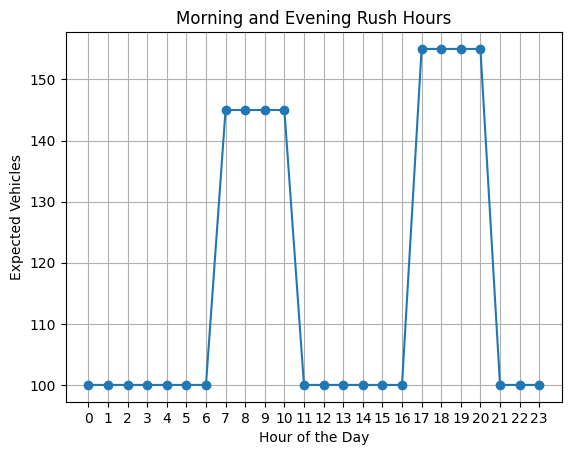

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
hour = np.arange(24)
morning_rush = np.where((hour >= 7) & (hour <= 10), 45, 0)
evening_rush = np.where((hour >= 17) & (hour <= 20), 55, 0)
traffic_rate = 100 + morning_rush + evening_rush
plt.plot(hour, traffic_rate, marker='o')
plt.xlabel("Hour of the Day")
plt.ylabel("Expected Vehicles")
plt.title("Morning and Evening Rush Hours")
plt.xticks(hour)
plt.grid(True)
plt.show()

In [ ]:
days = 30
junctions = 10
hours = 24
data = np.random.poisson(traffic_rate, (days, junctions, hours))
print("Shape:", data.shape)
print("Total records:", data.size)
print(data)

Shape: (30, 10, 24)
Total records: 7200
[[[ 96 107  88 ...  84  76  97]
  [111  93  87 ... 118 104 110]
  [115  94  91 ...  95 105 100]
  ...
  [112 108  85 ...  96  96 109]
  [ 98  86  79 ... 103 119  76]
  [ 96 103 111 ... 100  97 100]]

 [[ 99 100 104 ...  99  73 106]
  [100  85 101 ... 110  89 118]
  [102 108  95 ... 105  96  97]
  ...
  [ 94 107 102 ... 121  89 117]
  [106 121  95 ...  75  97 109]
  [ 98 121 103 ... 105 112  99]]

 [[111 105  93 ...  81  95 108]
  [108 100 105 ... 117 109  86]
  [105  90  80 ...  78 106 106]
  ...
  [110  94 107 ...  91 103  92]
  [103 106  98 ... 105 118  97]
  [101 101  84 ... 103  89  97]]

 ...

 [[ 82 105  97 ... 100  90 104]
  [112 116 108 ... 101  86 109]
  [ 98  91  93 ...  99  88 110]
  ...
  [103 100 107 ...  99  96 101]
  [109 101  84 ... 114  89  99]
  [109 121  91 ...  99 103 114]]

 [[ 98  97 102 ... 110 108 118]
  [ 92  89 101 ...  92  95  97]
  [117  99 104 ... 110  90  88]
  ...
  [100  86 110 ...  82  84  93]
  [113  93 109 ...  

In [ ]:
hourly_average = data.mean(axis=(0, 1))
junction_average = data.mean(axis=(0, 2))
peak_hour = hourly_average.argmax()
busiest_junction = junction_average.argmax()
print("Peak traffic hour:", peak_hour)
print("Peak traffic count:", hourly_average[peak_hour])
print("Busiest junction:", busiest_junction + 1)
print("Average junction traffic:", junction_average[busiest_junction])

Peak traffic hour: 19
Peak traffic count: 154.62333333333333
Busiest junction: 4
Average junction traffic: 117.28611111111111


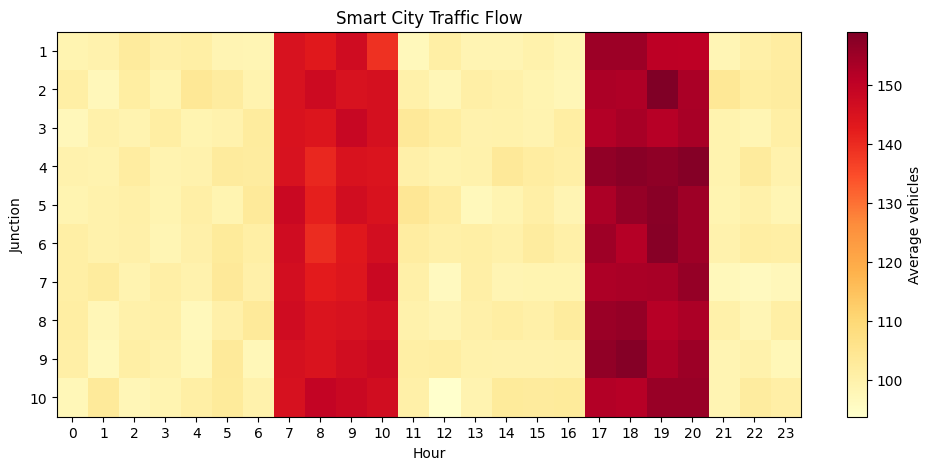

In [ ]:
plt.figure(figsize=(12, 5))
plt.imshow(data.mean(axis=0), aspect="auto", cmap="YlOrRd")
plt.colorbar(label="Average vehicles")
plt.xlabel("Hour")
plt.ylabel("Junction")
plt.title("Smart City Traffic Flow")
plt.xticks(np.arange(24))
plt.yticks(np.arange(10), np.arange(1, 11))
plt.show()

In [ ]:
def loop_average(data):
    result = []
    for j in range(10):
        total = 0
        for d in range(30):
            for h in range(24):
                total += data[d, j, h]
        result.append(total / (30 * 24))
    return result
def numpy_average(data):
    return data.mean(axis=(0, 2))
print("Loop result:", loop_average(data))
print("NumPy result:", numpy_average(data))
print("Loop execution time:")
%timeit loop_average(data)
print("NumPy execution time:")
%timeit numpy_average(data)

Loop result: [np.float64(115.75694444444444), np.float64(116.98194444444445), np.float64(116.47083333333333), np.float64(117.28611111111111), np.float64(116.7611111111111), np.float64(116.94444444444444), np.float64(116.09305555555555), np.float64(116.66805555555555), np.float64(116.69166666666666), np.float64(117.00972222222222)]
NumPy result: [115.75694444 116.98194444 116.47083333 117.28611111 116.76111111
 116.94444444 116.09305556 116.66805556 116.69166667 117.00972222]
Loop execution time:
2.31 ms ± 792 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
NumPy execution time:
32.6 µs ± 1.26 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)
